In [1]:
suppressPackageStartupMessages({
  library(dplyr)
  library(ggplot2)
  library(scales)
  library(patchwork)
})

# Soil Sediment Geochemistry - GLMM Analysis Pipeline
### Notebook 03 - Visualisations (publication style)

Figures are generated from the fitted models in Notebook 02 (`soil_glmm_models.rds`) plus the tidied data (`soil_tidied.rds`).
All figures are saved to `figures/` as **PNG at 300 dpi** and rendered inline.

Figure set:
1. Boxplots with individual observations, one figure per nutrient (SOC, Total N, Total P).
2. Treatment x period interaction plots from the Gamma GLMM (back-transformed EMMs, 95% CI).
3. Treatment-ratio forest plots (impact vs control ratio per period).
4. Combined three-nutrient overview panel.
5. DHARMa residual diagnostics (QQ + residuals vs predicted).


In [2]:
soil <- readRDS("soil_tidied.rds")
pack <- readRDS("soil_glmm_models.rds")
fits <- pack$fits

nut_order <- c("Carbon", "Nitrogen", "Phosphorus")
nut_lab   <- c(Carbon = "SOC", Nitrogen = "Total N", Phosphorus = "Total P")

dir.create("figures", showWarnings = FALSE)

theme_pub <- theme_bw(base_size = 12) +
  theme(
    panel.grid.minor   = element_blank(),
    panel.grid.major.x = element_blank(),
    strip.background   = element_rect(fill = "grey92", color = NA),
    strip.text         = element_text(face = "bold"),
    legend.position    = "top",
    legend.title       = element_text(face = "bold"),
    plot.title         = element_text(face = "bold", size = 13),
    plot.subtitle      = element_text(size = 10, color = "grey25")
  )

cols_fill <- NULL
cols_line <- NULL
scan_pal <- c(C = "#66C2A5", c = "#66C2A5", I = "#FC8D62", i = "#FC8D62")
cat("Theme ready. Figures directory: figures/\n")

Theme ready. Figures directory: figures/


## 1 - Raw data: boxplots with individual observations


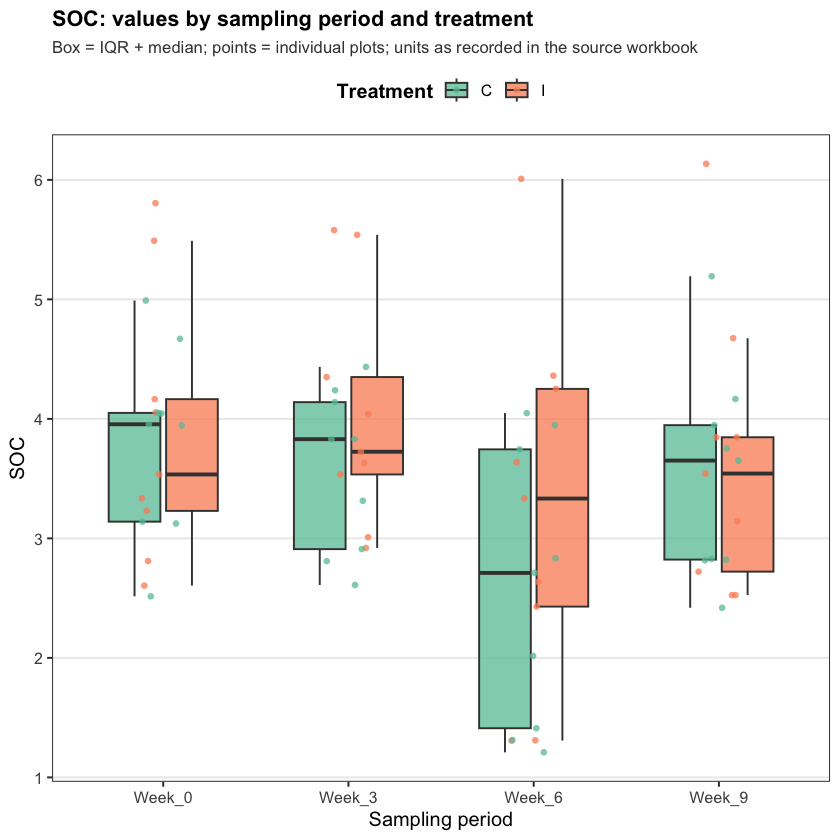

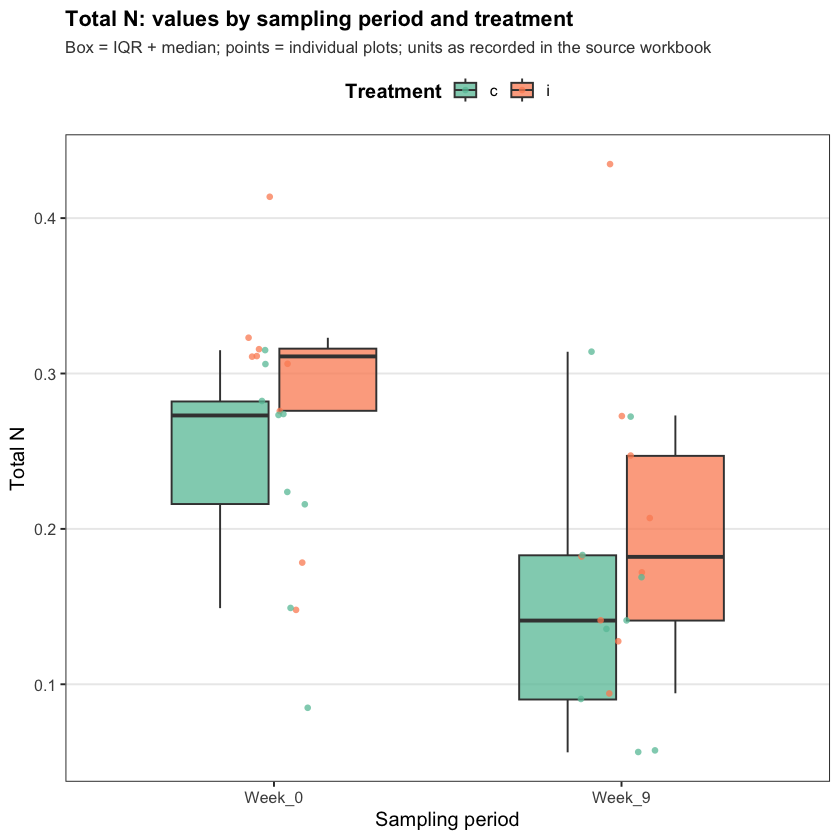


Saved: figures/fig_carbon_boxplot.png, figures/fig_nitrogen_boxplot.png, figures/fig_phosphorus_boxplot.png 


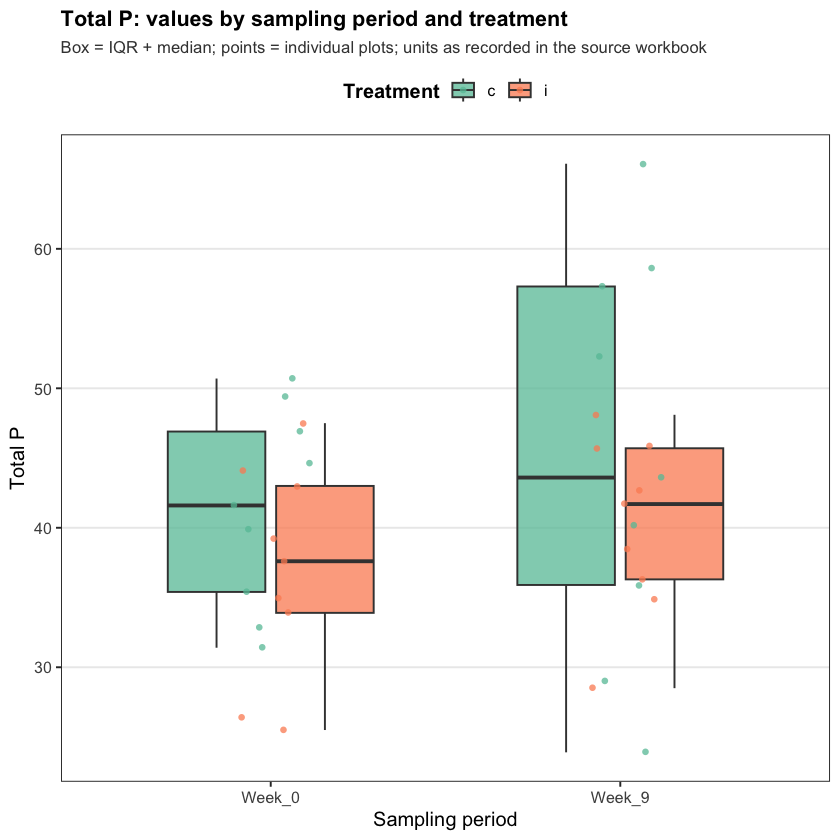

In [3]:
fig_box_files <- c()
for (nm in nut_order) {
  d <- soil %>% filter(nutrient == nm)
  p <- ggplot(d, aes(x = period, y = response, fill = treatment)) +
    geom_boxplot(outlier.shape = NA, alpha = 0.75, width = 0.62, color = "grey25") +
    geom_jitter(aes(colour = treatment), width = 0.12, size = 1.5, alpha = 0.75, shape = 16) +
    scale_fill_manual(values = scan_pal) +
    scale_colour_manual(values = scan_pal) +
    labs(
      title    = sprintf("%s: values by sampling period and treatment", nut_lab[[nm]]),
      subtitle = "Box = IQR + median; points = individual plots; units as recorded in the source workbook",
      x        = "Sampling period",
      y        = nut_lab[[nm]],
      fill     = "Treatment", colour = "Treatment"
    ) +
    theme_pub
  fn <- sprintf("figures/fig_%s_boxplot.png", tolower(nm))
  ggsave(fn, p, width = 7.2, height = 5, dpi = 300)
  fig_box_files <- c(fig_box_files, fn)
  print(p)
}
cat("\nSaved:", paste(fig_box_files, collapse = ", "), "\n")

## 2 - Model-based means: treatment x period interaction (response scale)

Back-transformed estimated marginal means from the Gamma GLMM (log link) with 95% CIs.


Loading required namespace: emmeans



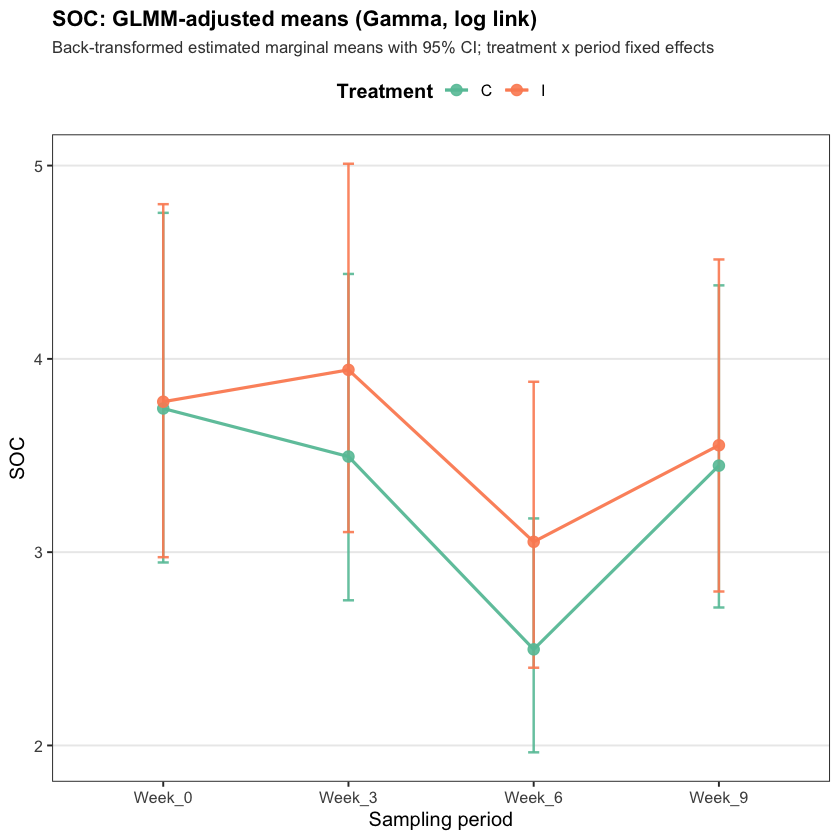

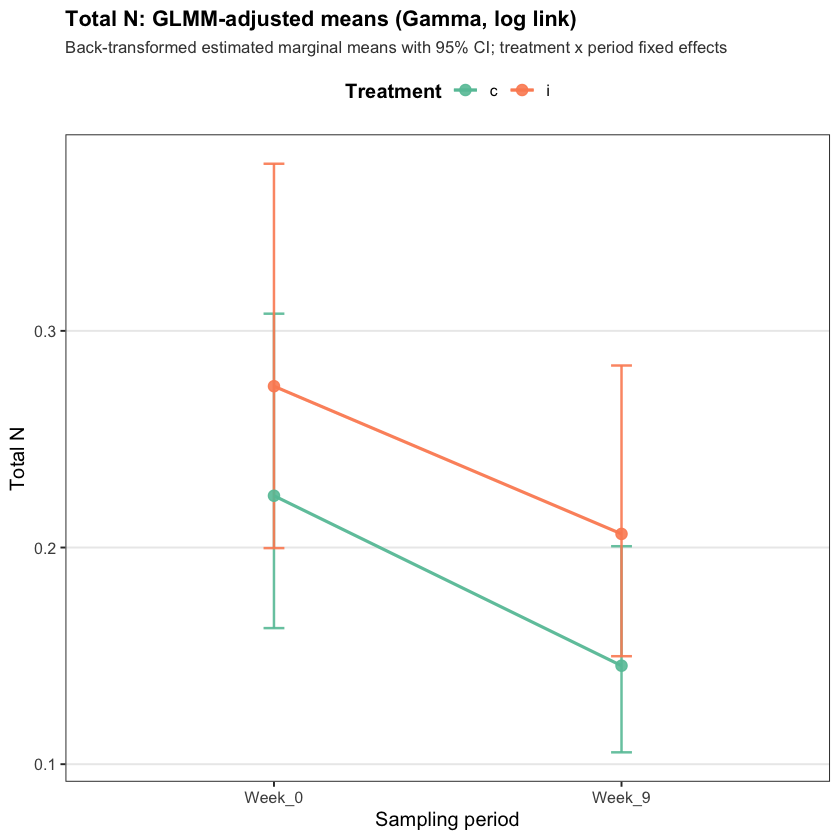


Saved: figures/fig_carbon_interaction_means.png, figures/fig_nitrogen_interaction_means.png, figures/fig_phosphorus_interaction_means.png 


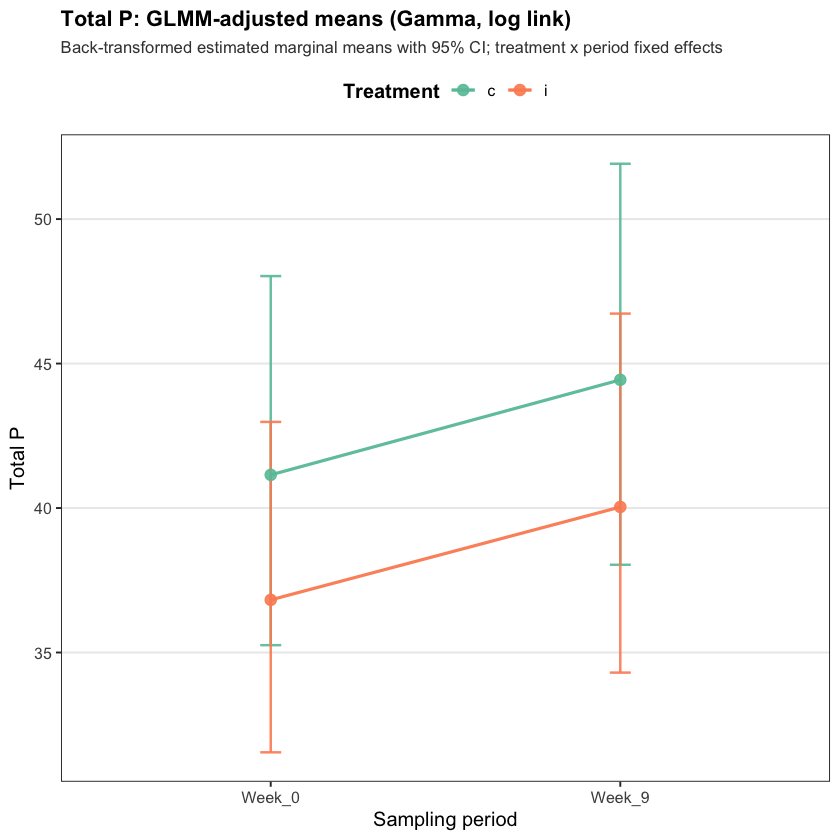

In [4]:
emm_fig_df <- bind_rows(lapply(nut_order, function(nm) {
  d <- as.data.frame(summary(pack$emm[[nm]], level = 0.95, infer = c(TRUE, TRUE)))
  names(d)[names(d) %in% c("response", "emmean", "rate")] <- "mean"
  names(d)[names(d) == "asymp.LCL"] <- "lower.CL"
  names(d)[names(d) == "asymp.UCL"] <- "upper.CL"
  d$nutrient <- nm
  d
}))

fig_int_files <- c()
for (nm in nut_order) {
  d <- emm_fig_df %>% filter(nutrient == nm)
  p <- ggplot(d, aes(x = period, y = mean, group = treatment, colour = treatment)) +
    geom_errorbar(aes(ymin = lower.CL, ymax = upper.CL), width = 0.06, linewidth = 0.7, alpha = 0.9) +
    geom_line(linewidth = 0.9, alpha = 0.95) +
    geom_point(size = 2.8, alpha = 0.9) +
    scale_colour_manual(values = scan_pal) +
    labs(
      title    = sprintf("%s: GLMM-adjusted means (Gamma, log link)", nut_lab[[nm]]),
      subtitle = "Back-transformed estimated marginal means with 95% CI; treatment x period fixed effects",
      x        = "Sampling period",
      y        = nut_lab[[nm]],
      colour   = "Treatment"
    ) +
    theme_pub
  fn <- sprintf("figures/fig_%s_interaction_means.png", tolower(nm))
  ggsave(fn, p, width = 7.2, height = 5, dpi = 300)
  fig_int_files <- c(fig_int_files, fn)
  print(p)
}
cat("\nSaved:", paste(fig_int_files, collapse = ", "), "\n")

## 3 - Treatment-ratio forest plot (control vs impact per period)

Ratio = control-type / impact-type from `pairs()` on the response scale. Ratio > 1: control-type higher; ratio < 1: impact-type higher.


Warning message:
“`geom_errorbarh()` was deprecated in ggplot2 4.0.0.
ℹ Please use the `orientation` argument of `geom_errorbar()` instead.”


`height` was translated to `width`.


`height` was translated to `width`.


`height` was translated to `width`.


`height` was translated to `width`.


`height` was translated to `width`.


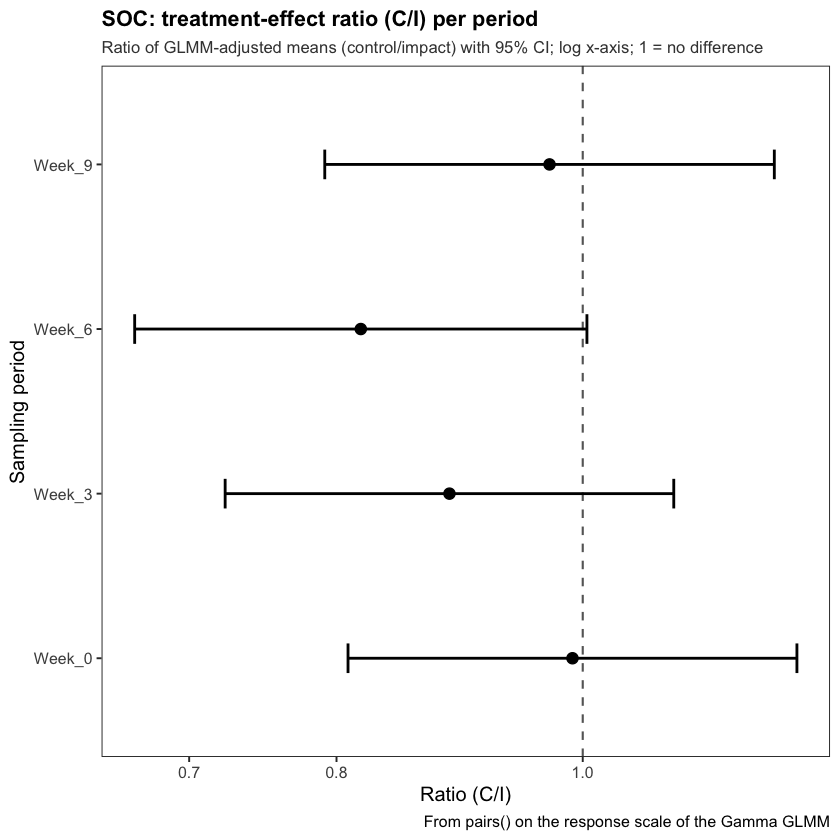

`height` was translated to `width`.


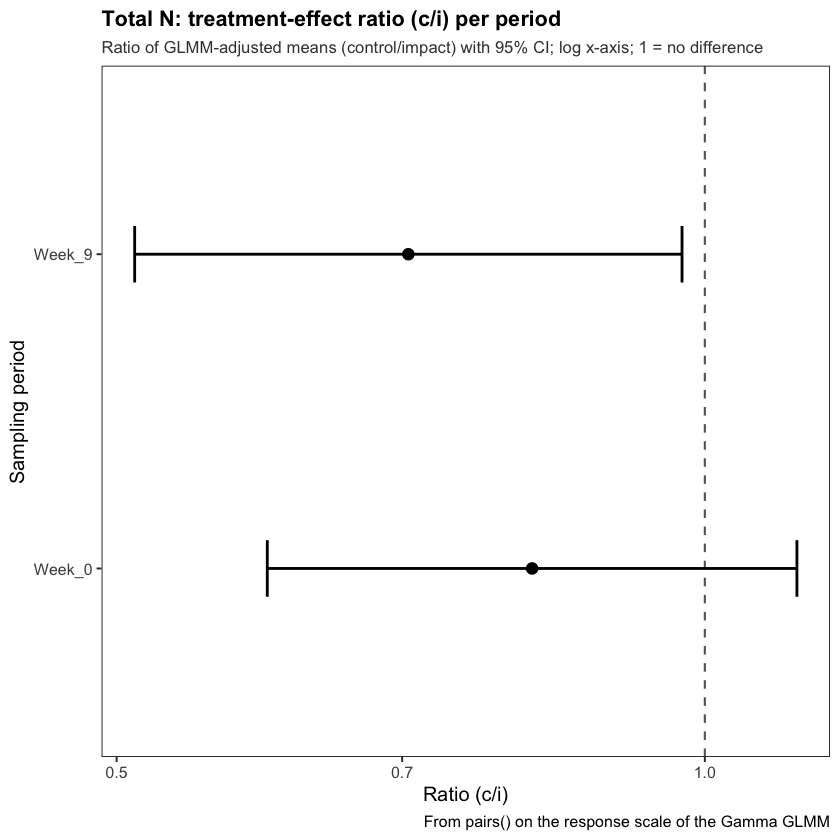


Saved: figures/fig_carbon_ratio_forest.png, figures/fig_nitrogen_ratio_forest.png, figures/fig_phosphorus_ratio_forest.png 


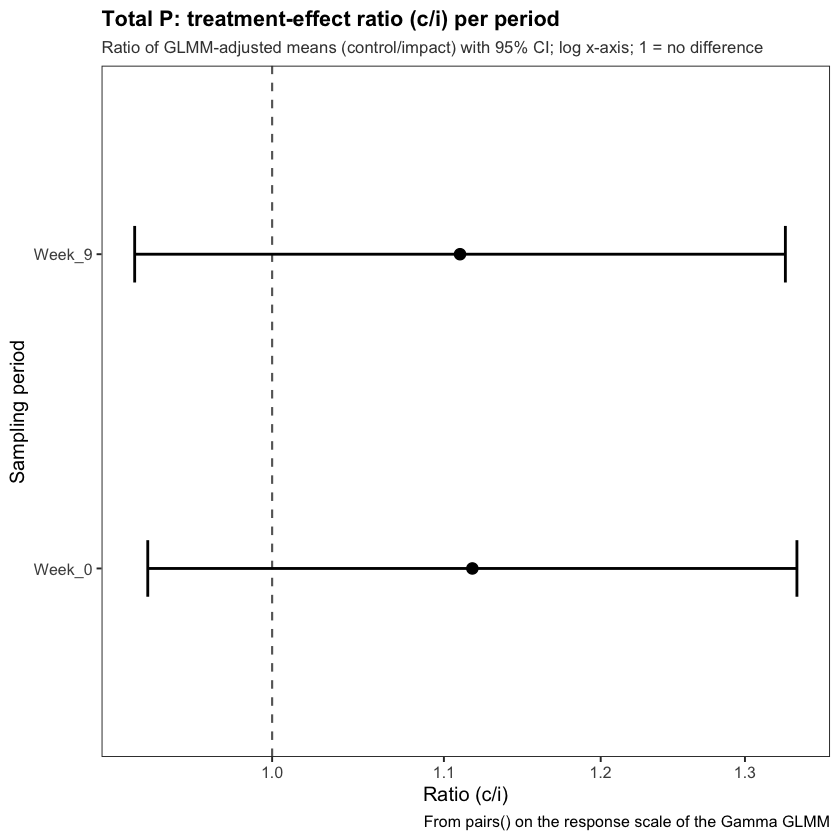

In [5]:
pair_fig_df <- bind_rows(lapply(nut_order, function(nm) {
  s <- as.data.frame(summary(pairs(pack$emm[[nm]]), infer = c(TRUE, TRUE), type = "response", adjust = "holm"))
  s$nutrient <- nm
  s
}))
estcol <- intersect(names(pair_fig_df), c("ratio", "effect", "odds.ratio"))[1]
if (is.na(estcol)) estcol <- names(pair_fig_df)[sapply(pair_fig_df, is.numeric)][1]
names(pair_fig_df)[names(pair_fig_df) == estcol] <- "ratio"
names(pair_fig_df)[names(pair_fig_df) %in% c("asymp.LCL", "lower.CL", "lower")] <- "LCL"
names(pair_fig_df)[names(pair_fig_df) %in% c("asymp.UCL", "upper.CL", "upper")] <- "UCL"
trt_ref <- c(Carbon = "C/I", Nitrogen = "c/i", Phosphorus = "c/i")

fig_ratio_files <- c()
for (nm in nut_order) {
  d <- pair_fig_df %>% filter(nutrient == nm)
  p <- ggplot(d, aes(x = ratio, y = period)) +
    geom_vline(xintercept = 1, linetype = "dashed", color = "grey40", linewidth = 0.6) +
    geom_errorbarh(aes(xmin = LCL, xmax = UCL), height = 0.18, linewidth = 0.8, color = "black") +
    geom_point(size = 2.8, color = "black") +
    scale_x_log10() +
    labs(
      title    = sprintf("%s: treatment-effect ratio (%s) per period", nut_lab[[nm]], trt_ref[[nm]]),
      subtitle = "Ratio of GLMM-adjusted means (control/impact) with 95% CI; log x-axis; 1 = no difference",
      x        = sprintf("Ratio (%s)", trt_ref[[nm]]),
      y        = "Sampling period",
      caption  = "From pairs() on the response scale of the Gamma GLMM"
    ) +
    theme_pub +
    theme(axis.text.y = element_text(angle = 0), panel.grid.major.y = element_blank())
  fn <- sprintf("figures/fig_%s_ratio_forest.png", tolower(nm))
  ggsave(fn, p, width = 7, height = 4.4, dpi = 300)
  fig_ratio_files <- c(fig_ratio_files, fn)
  print(p)
}
cat("\nSaved:", paste(fig_ratio_files, collapse = ", "), "\n")

## 4 - Combined overview (three nutrients, free y-scales)


Saved: figures/fig_overview.png


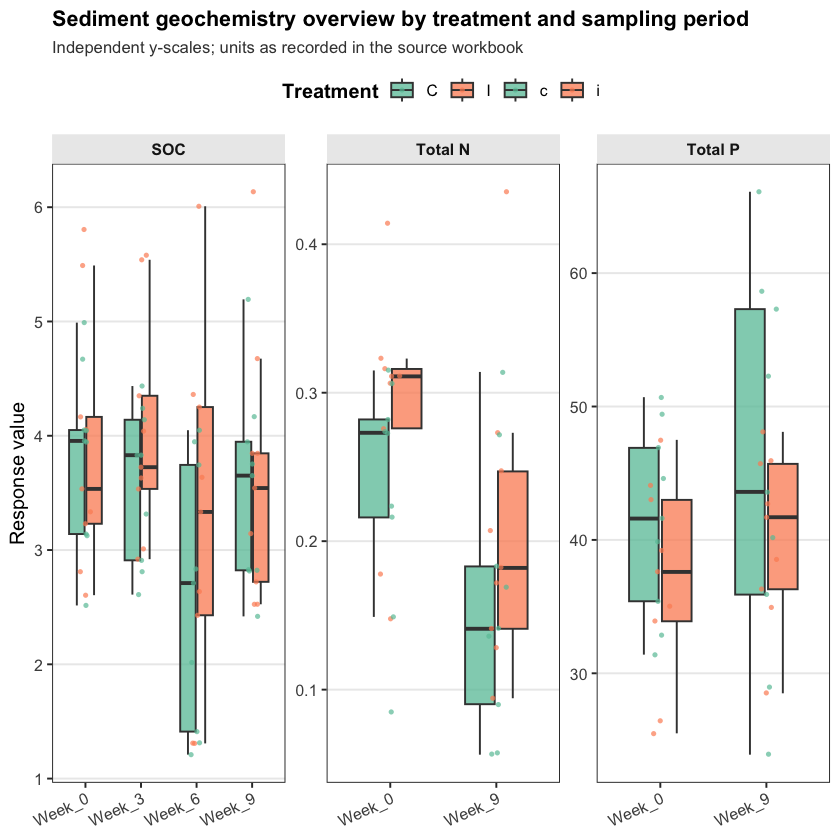

In [6]:
ov <- soil %>%
  filter(nutrient %in% nut_order) %>%
  group_by(nutrient) %>%
  mutate(period = droplevels(period)) %>%
  ungroup() %>%
  mutate(panel = nut_lab[nutrient])

p_ov <- ggplot(ov, aes(x = period, y = response, fill = treatment)) +
  geom_boxplot(outlier.shape = NA, alpha = 0.75, width = 0.62, color = "grey25") +
  geom_jitter(aes(colour = treatment), width = 0.1, size = 1.1, alpha = 0.7, shape = 16) +
  scale_fill_manual(values = scan_pal) +
  scale_colour_manual(values = scan_pal) +
  facet_wrap(~ panel, scales = "free", nrow = 1) +
  labs(
    title    = "Sediment geochemistry overview by treatment and sampling period",
    subtitle = "Independent y-scales; units as recorded in the source workbook",
    x        = NULL,
    y        = "Response value",
    fill     = "Treatment", colour = "Treatment"
  ) +
  theme_pub +
  theme(axis.text.x = element_text(angle = 25, hjust = 1))

ggsave("figures/fig_overview.png", p_ov, width = 11.5, height = 4.6, dpi = 300)
cat("Saved: figures/fig_overview.png\n")
print(p_ov)

## 5 - DHARMa residual diagnostics (all nutrients)

Left: residuals (log-predicted scale) vs scaled residuals (0-1; median = 0.5 line).
Right: QQ plot of scaled residuals against U(0,1) quantiles.


Saved: figures/fig_diagnostics.png



DHARMa test summary (from Notebook 02):


    panel   KS_p dispersion_p outliers_p
1     SOC 0.0645        0.958          1
2 Total N 0.2040        0.800          1
3 Total P 0.9160        0.508          1


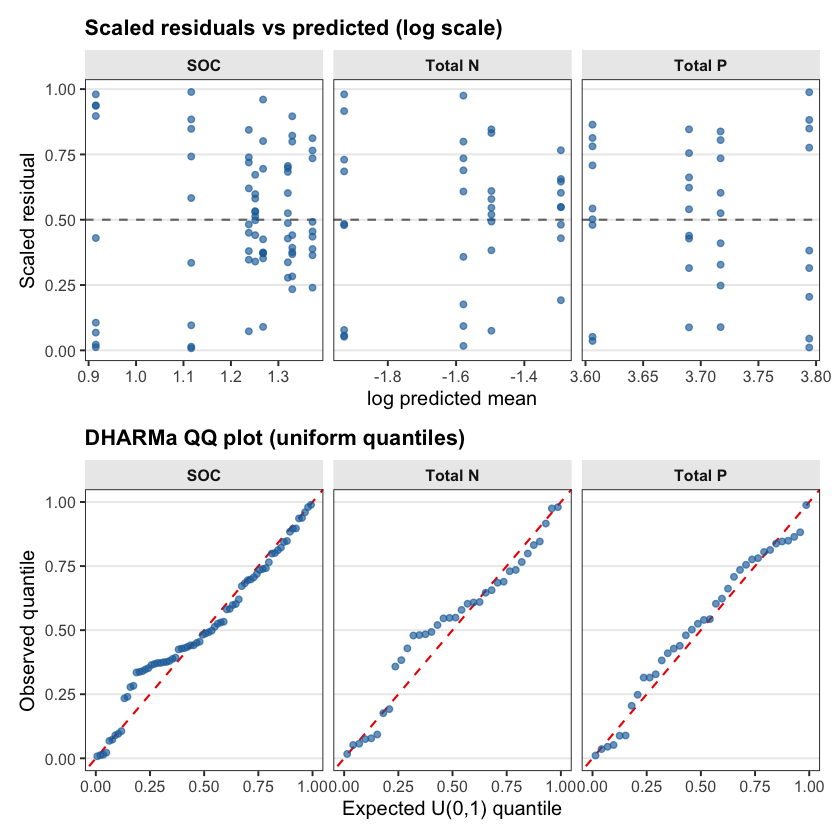

In [7]:
sim_meta <- bind_rows(lapply(nut_order, function(nm) {
  d <- pack$dh_tab %>% filter(nutrient == nm)
  d$panel <- nut_lab[[nm]]
  d
}))

diag_res <- bind_rows(lapply(nut_order, function(nm) {
  s  <- pack$sims[[nm]]
  fv <- s$fittedPredictedResponse
  if (is.null(fv) || length(fv) == 0) fv <- s$fittedResponse
  data.frame(nutrient = nm,
             panel    = nut_lab[[nm]],
             fitted   = log(as.numeric(fv)),
             resid    = as.numeric(s$scaledResiduals))
}))

diag_qq <- bind_rows(lapply(nut_order, function(nm) {
  s   <- pack$sims[[nm]]
  r   <- as.numeric(s$scaledResiduals)
  n   <- length(r)
  data.frame(nutrient = nm,
             panel    = nut_lab[[nm]],
             expected = ppoints(n),
             observed = sort(r))
}))

p_res <- ggplot(diag_res, aes(x = fitted, y = resid)) +
  geom_hline(yintercept = 0.5, linetype = "dashed", color = "grey45", linewidth = 0.6) +
  geom_point(size = 1.5, alpha = 0.65, color = "#1B6CA8") +
  facet_wrap(~ panel, scales = "free_x") +
  labs(title = "Scaled residuals vs predicted (log scale)", x = "log predicted mean", y = "Scaled residual") +
  theme_pub

p_qq <- ggplot(diag_qq, aes(x = expected, y = observed)) +
  geom_abline(slope = 1, intercept = 0, linetype = "dashed", color = "red2", linewidth = 0.6) +
  geom_point(size = 1.5, alpha = 0.65, color = "#1B6CA8") +
  xlim(0, 1) + ylim(0, 1) +
  facet_wrap(~ panel) +
  labs(title = "DHARMa QQ plot (uniform quantiles)", x = "Expected U(0,1) quantile", y = "Observed quantile") +
  theme_pub

p_diag <- p_res / p_qq + plot_layout(guides = "collect") & theme_pub
ggsave("figures/fig_diagnostics.png", p_diag, width = 10, height = 8.4, dpi = 300)
cat("Saved: figures/fig_diagnostics.png\n")
print(p_diag)

cat("\nDHARMa test summary (from Notebook 02):\n")
print(as.data.frame(sim_meta %>% select(panel, KS_p, dispersion_p, outliers_p)))

## 6 - Figure inventory


In [8]:
figs <- list.files("figures", full.names = TRUE)
tab     <- data.frame(file = figs, size_kb = round(file.info(figs)$size / 1024, 1))
print(tab, row.names = FALSE)
cat("\nAll figures saved at 300 dpi PNG in figures/.\n")

                                         file size_kb
               figures/fig_carbon_boxplot.png    98.0
     figures/fig_carbon_interaction_means.png   121.1
          figures/fig_carbon_ratio_forest.png    88.1
                  figures/fig_diagnostics.png   377.5
             figures/fig_nitrogen_boxplot.png    80.2
   figures/fig_nitrogen_interaction_means.png   100.3
        figures/fig_nitrogen_ratio_forest.png    75.8
                     figures/fig_overview.png   170.2
           figures/fig_phosphorus_boxplot.png    81.3
 figures/fig_phosphorus_interaction_means.png    86.7
      figures/fig_phosphorus_ratio_forest.png    76.2



All figures saved at 300 dpi PNG in figures/.
